# UTS Data Mining: Prediksi Kualitas Anggur


## 1. Persiapan Data
Pertama, import library dan baca kedua dataset.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

train = pd.read_csv('data_training.csv')
test = pd.read_csv('data_testing.csv')

print('Ukuran data training:', train.shape)
print('Ukuran data testing :', test.shape)
train.head()

Ukuran data training: (857, 13)
Ukuran data testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


Data training punya 857 baris dan 13 kolom (11 fitur kimia + `quality` + `Id`). Data testing punya 286 baris dan 12 kolom.

## 2. Pembersihan Data
Cek missing values, data duplikat, dan tipe data.

In [22]:
print('Missing values data training:', train.isna().sum().sum())
print('Missing values data testing :', test.isna().sum().sum())
print('Baris duplikat di training  :', train.drop(columns='Id').duplicated().sum(), '(tidak menghitung kolom Id)')
print()
print(train.dtypes)

Missing values data training: 0
Missing values data testing : 0
Baris duplikat di training  : 76 (tidak menghitung kolom Id)

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object


Tidak ada misiing value di kedua dataset, dan semua kolom bertipe numerik.

### Cek outlier
Untuk melihat sebaran tiap fitur lewat boxplot.

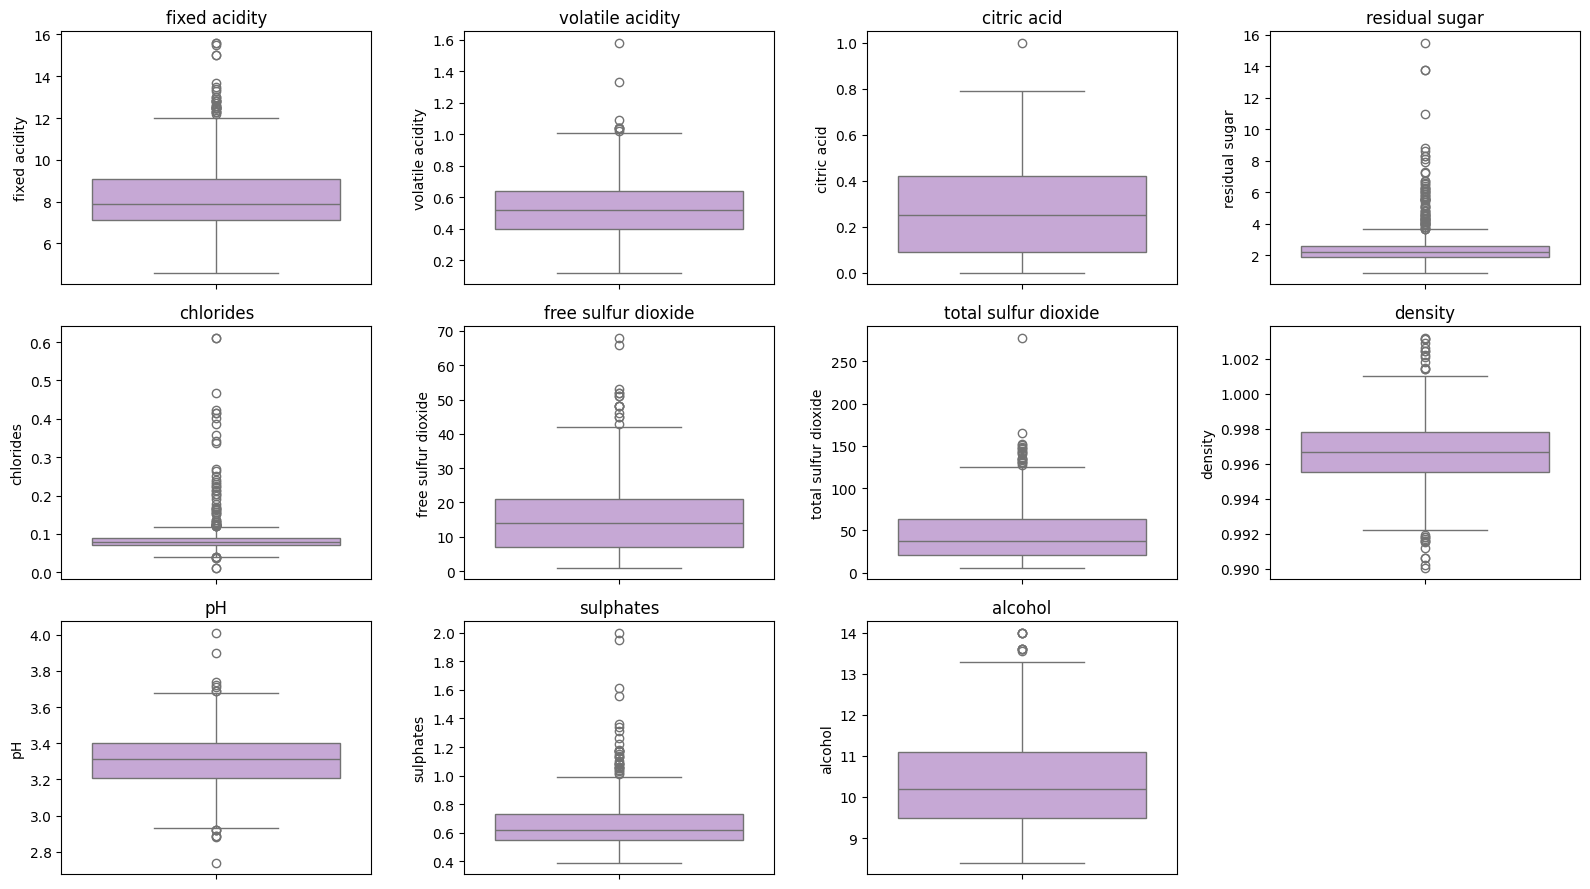

In [23]:
fitur = [c for c in train.columns if c not in ['quality', 'Id']]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), fitur):
    sns.boxplot(y=train[col], ax=ax, color='#c9a0dc')
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

Beberapa fitur punya banyak titik di luar boxplot, terutama `residual sugar`, `chlorides`, `sulphates`, dan `fixed acidity`.

## 3. Eksplorasi Singkat

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


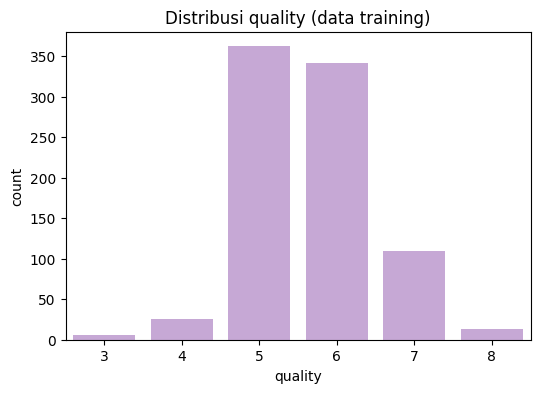

In [24]:
print(train['quality'].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(x='quality', data=train, color='#c9a0dc')
plt.title('Distribusi quality (data training)')
plt.show()

Kelasnya **tidak seimbang**. Hampir semua anggur ada di kualitas 5 dan 6 (703 dari 857 data), kualitas 7 lumayan, sedangkan kualitas 3, 4, dan 8 sangat sedikit (hanya 6, 26, dan 13 data).

Ini akan berpengaruh ke model: dia cenderung jago nebak kelas 5 dan 6, tapi kesulitan menebak kelas yang jarang muncul.

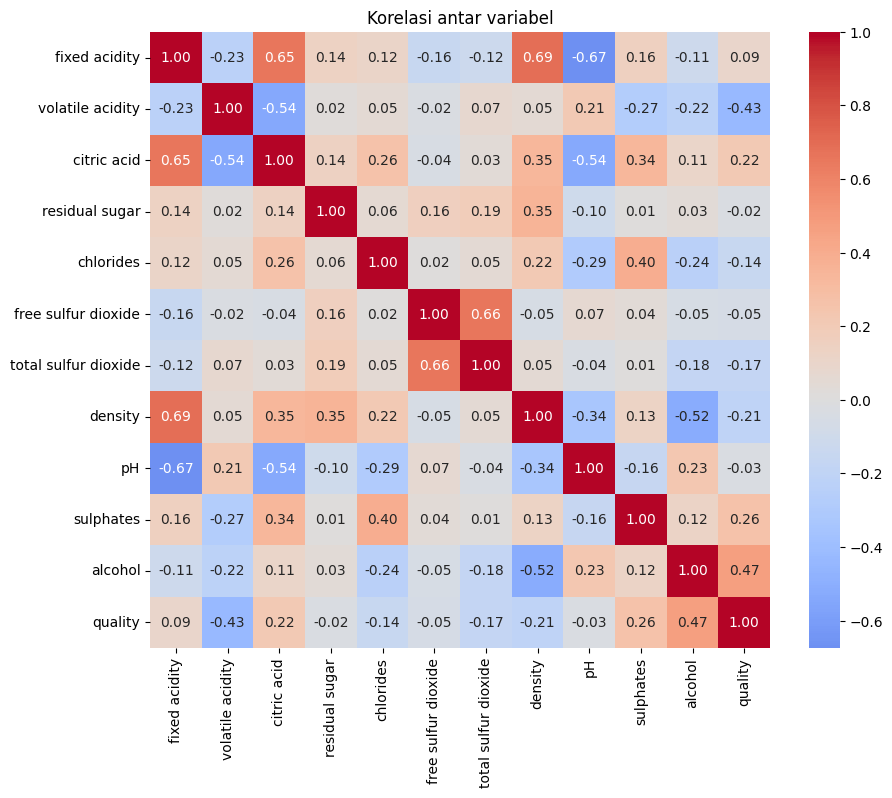

volatile acidity       -0.430059
density                -0.207903
total sulfur dioxide   -0.172737
chlorides              -0.144946
free sulfur dioxide    -0.054509
pH                     -0.033199
residual sugar         -0.020511
fixed acidity           0.092714
citric acid             0.221263
sulphates               0.260703
alcohol                 0.473555
Name: quality, dtype: float64


In [25]:
plt.figure(figsize=(10, 8))
sns.heatmap(train.drop(columns='Id').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi antar variabel')
plt.show()

print(train.drop(columns='Id').corr()['quality'].drop('quality').sort_values())

Fitur yang paling berhubungan dengan `quality`:
- `alcohol` (korelasi positif, sekitar 0,47): makin tinggi alkohol, cenderung makin bagus kualitasnya.
- `volatile acidity` (korelasi negatif, sekitar -0,43): makin tinggi keasaman volatil (bau cuka), makin jelek kualitasnya.
- `sulphates` dan `citric acid` berkorelasi positif yang lebih lemah.

Korelasi paling tinggi hanya sekitar 0,47, artinya tidak ada satu fitur yang cukup untuk menebak kualitas. Jadi memang perlu model yang menggabungkan semua fitur.

## 4. Feature Scaling

In [26]:
print(train[fitur].agg(['min', 'max']).T)

                          min       max
fixed acidity         4.60000   15.6000
volatile acidity      0.12000    1.5800
citric acid           0.00000    1.0000
residual sugar        0.90000   15.5000
chlorides             0.01200    0.6110
free sulfur dioxide   1.00000   68.0000
total sulfur dioxide  6.00000  278.0000
density               0.99007    1.0032
pH                    2.74000    4.0100
sulphates             0.39000    2.0000
alcohol               8.40000   14.0000


Skala antar fitur beda jauh.

Contohnya `total sulfur dioxide` bisa sampai 278, sedangkan `density` cuma sekitar 0,99 sampai 1,00. Untuk model yang bergantung pada jarak atau koefisien (KNN, SVM, Logistic Regression), ini masalah karena fitur berskala besar akan mendominasi.

Makanya untuk model-model itu saya pakai `StandardScaler` (data diubah jadi rata-rata 0 dan simpangan baku 1).

Sedangkan model berbasis pohon (Random Forest, Extra Trees, Gradient Boosting) tidak terpengaruh skala, karena cuma membandingkan nilai ambang di satu fitur. Jadi scaling tidak diperlukan untuk model pohon. Scaler dimasukkan ke dalam `pipeline` supaya cuma di-fit pakai data training dan tidak bocor ke data validasi.

## 5. Pembuatan Model & Evaluasi

Saya membandingkan 7 model.

Evaluasinya pakai **5-fold stratified cross-validation**, jadi setiap model diuji 5 kali di bagian data yang tidak dipakai untuk training.

In [27]:
X = train.drop(columns=['quality', 'Id'])
y = train['quality']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'SVM': make_pipeline(StandardScaler(), SVC()),
    'Random Forest': RandomForestClassifier(n_estimators=500, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=500, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

hasil = []
for nama, m in models.items():
    skor = cross_val_score(m, X, y, cv=cv, scoring='accuracy')
    hasil.append({'Model': nama, 'Akurasi rata-rata': skor.mean(), 'Std': skor.std()})

hasil = pd.DataFrame(hasil).sort_values('Akurasi rata-rata', ascending=False).reset_index(drop=True)
hasil

,Model,Akurasi rata-rata,Std
0,Extra Trees,0.648796,0.027696
1,Random Forest,0.641840,0.038453
2,SVM,0.609146,0.033028
3,Gradient Boosting,0.607942,0.013718
4,Logistic Regression,0.595131,0.045114
5,KNN,0.563695,0.038451


Model berbasis pohon, yaitu **Extra Trees dan Random Forest**, hasilnya paling bagus (sekitar 64 sampai 65%), mengalahkan model linear/jarak yang hanya sekitar 56 sampai 61%.

Masuk akal karena hubungan antara senyawa kimia anggur dan kualitasnya tidak linear dan banyak interaksi antar fitur, yang bisa ditangkap pohon.

Akurasi sekitar 65% mungkin terlihat rendah, tapi untuk dataset wine quality ini wajar, karena penilaian kualitas itu subjektif (nilai dari penguji manusia) dan kelasnya tidak seimbang.

Dua model teratas akan dibawa ke tahap tuning.

### Evaluasi detail dengan hold-out
Agar bisa melihat confusion matrix, data training dibagi 80% untuk latihan dan 20% untuk validasi.

In [28]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

et = ExtraTreesClassifier(n_estimators=500, random_state=42)
et.fit(X_tr, y_tr)
pred_val = et.predict(X_val)

print('Akurasi validasi :', round(accuracy_score(y_val, pred_val), 4))
print('Akurasi training :', round(accuracy_score(y_tr, et.predict(X_tr)), 4))
print()
print(classification_report(y_val, pred_val, zero_division=0))

Akurasi validasi : 0.6105
Akurasi training : 1.0

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.64      0.79      0.71        73
           6       0.57      0.57      0.57        68
           7       0.54      0.32      0.40        22
           8       1.00      0.33      0.50         3

    accuracy                           0.61       172
   macro avg       0.46      0.34      0.36       172
weighted avg       0.59      0.61      0.59       172



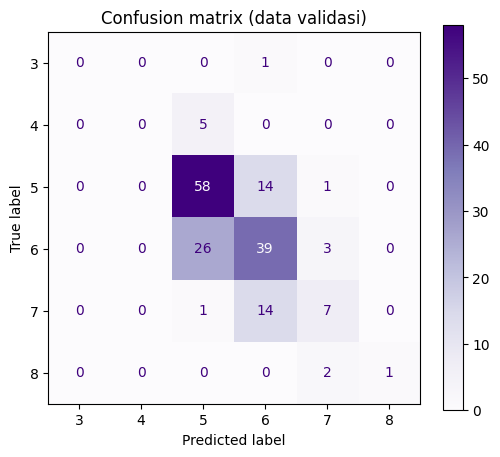

In [29]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, ax=ax, cmap='Purples')
plt.title('Confusion matrix (data validasi)')
plt.show()

**Hasilnya:**
- Akurasi training 100% sedangkan akurasi validasi cuma sekitar 61% (hasil satu kali pembagian data, jadi agak berfluktuasi dibanding rata-rata CV sekitar 65%). Ini tanda model sedikit **overfitting** (hafal data latihan). Makanya evaluasi harus di data yang tidak dilihat model, bukan di data training.

- Dari confusion matrix, model bagus di kelas **5 dan 6** (kelas mayoritas), lumayan di kelas 7, dan gagal menebak kelas 3 dan 4 (nol yang benar). Kelas 8 cuma kebetulan kena 1 dari 3 sampel, jadi tidak bisa dibilang bisa diandalkan. Itu efek dari kelas yang tidak seimbang tadi: contoh datanya terlalu sedikit buat dipelajari.

- Kesalahan paling sering cuma meleset satu tingkat (5 tertukar dengan 6, atau 6 tertukar demgan 7), yang wajar karena batas antar kualitas memang tipis.

## 6. Tuning Model
Mencoba mencari hyperparameter terbaik untuk Extra Trees dan Random Forest menggunakan `RandomizedSearchCV` (5-fold CV).

In [30]:
param = {
    'n_estimators': [300, 500, 800],
    'max_depth': [None, 10, 15, 20],
    'min_samples_leaf': [1, 2, 3],
    'max_features': ['sqrt', 'log2', 0.5],
}

kandidat = {
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

tuned = {}
for nama, m in kandidat.items():
    rs = RandomizedSearchCV(m, param, n_iter=20, cv=cv, scoring='accuracy',
                            random_state=42, n_jobs=-1)
    rs.fit(X, y)
    tuned[nama] = rs
    print(nama, '| akurasi CV terbaik:', round(rs.best_score_, 4))
    print('   parameter:', rs.best_params_)

Extra Trees | akurasi CV terbaik: 0.65
   parameter: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}
Random Forest | akurasi CV terbaik: 0.6477
   parameter: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 15}


Tuning hanya menaikkan akurasi yang sangat tipis dibanding pengaturan awal (Extra Trees dari sekitar 64,9% jadi 65,0%, Random Forest dari sekitar 64,2% jadi 64,8%), jadi selisihnya hampir nggak berarti.

Artinya model sudah mentok di batas kemampuan data ini, dan sisanya lebih ditentukan oleh kualitas data (jumlah sampel, kelas langka) daripada pengaturan model. Saya pilih model dengan akurasi CV tertinggi sebagai model final.

Model final: Extra Trees
Akurasi CV : 0.65


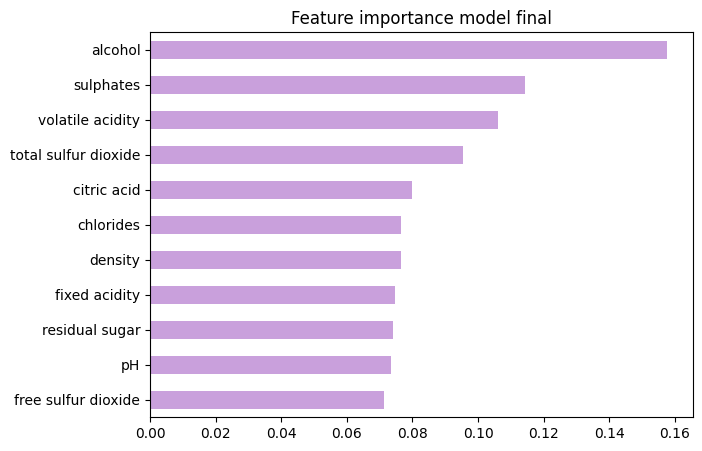

In [31]:
nama_terbaik = max(tuned, key=lambda k: tuned[k].best_score_)
model_final = tuned[nama_terbaik].best_estimator_
print('Model final:', nama_terbaik)
print('Akurasi CV :', round(tuned[nama_terbaik].best_score_, 4))

# latih ulang model final pakai SEMUA data training
model_final.fit(X, y)

imp = pd.Series(model_final.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', figsize=(7, 5), color='#c9a0dc')
plt.title('Feature importance model final')
plt.show()

Fitur yang paling berpengaruh untuk model adalah `alcohol`, `sulphates`, dan `volatile acidity`, sejalan dengan hasil korelasi tadi. Jadi secara kimia, kadar alkohol, sulfat, dan keasaman volatil adalah petunjuk utama kualitas anggur di data ini.

Setelah dipilih, model dilatih ulang memggunakan seluruh data training (bukan cuma 80%) supaya memanfaatkan semua informasi yang ada.

## 7. Simpan Model

In [36]:
joblib.dump(model_final, 'model_wine.pkl', compress=3)
print('Model tersimpan: model_wine.pkl')

Model tersimpan: model_wine.pkl


Model disimpan ke `model_wine.pkl` menggunakan `joblib`, jadi nanti bisa dipakai lagi tanpa training ulang.

## 8. Prediksi Data Uji & File Hasil

In [33]:
# load lagi model yang sudah disimpan (simulasi deployment)
model_load = joblib.load('model_wine.pkl')

# pakai kolom fitur yang sama dengan waktu training (Id tidak ikut)
X_test = test[X.columns]
pred_test = model_load.predict(X_test)

print('Jumlah prediksi:', len(pred_test))
print(pd.Series(pred_test).value_counts().sort_index())

Jumlah prediksi: 286
4      1
5    132
6    122
7     31
Name: count, dtype: int64


Distribusi prediksi mirip pola data training, mayoritas di kualitas 5 dan 6 lalu 7. Seperti yang sudah dibahas, model hampir tidak pernah memprediksi kualitas ekstrem (3, 4, 8).

In [34]:
format_df = pd.read_csv('hasilprediksi_017.csv', sep=';')
print('Kolom template:', list(format_df.columns))

hasil_df = pd.DataFrame({'Id': test['Id'], 'Quality': pred_test})

assert set(format_df['Id']) == set(hasil_df['Id']), 'Id tidak cocok dengan template!'
hasil_df = format_df[['Id']].merge(hasil_df, on='Id', how='left')

assert hasil_df['Quality'].notna().all()
hasil_df.to_csv('hasilprediksi_017.csv', index=False, sep=';')

print('Tersimpan: hasilprediksi_017.csv', hasil_df.shape)
hasil_df.head()

Kolom template: ['Id', 'Quality']
Tersimpan: hasilprediksi_017.csv (286, 2)


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5


## Kesimpulan
- Data tanpa missing value (ada 76 baris duplikat yang dipertahankan), tapi kelasnya tidak seimbang.
- Scaling diperlukan untuk model linear/jarak, tapi tidak untuk model pohon.
- Model terbaik adalah model berbasis pohon (Extra Trees/Random Forest) dengan akurasi CV sekitar 65% (hold-out sekitar 61%).
- Fitur paling penting: `alcohol`, `sulphates`, `volatile acidity`.
- Keterbatasan: model sulit memprediksi kualitas langka (3, 4, 8) karena contohnya sedikit. Ke depannya bisa dicoba teknik penyeimbangan kelas (misalnya `class_weight` atau oversampling), atau pengumpulan data yang lebih banyak.

##Unduh Hasil

In [37]:
from google.colab import files
files.download('hasilprediksi_017.csv')
files.download('model_wine.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>